# Pneumonia Detection with Frequency-Domain (FFT) Preprocessing — Corrected Experiment

**Research question.** Do CNNs trained on frequency-filtered chest X-rays generalize better to an unseen dataset than CNNs trained on raw images?

**What this revision fixes (summary).**

1. **No test-set leakage.** The original notebooks used the Kaggle `test` folder as the *validation* set for early stopping, checkpointing, and threshold selection. Here, the validation set is a *patient-grouped* split of the training folder. The test sets are touched only once, for final reporting.
2. **Honest batch-norm handling.** `base(inputs, training=True)` forced BatchNorm into training mode, so predictions depended on batch statistics. Here the backbone is called with `training=False` (standard practice for fine-tuning with small batches).
3. **Augmentation applied correctly.** Augmentation was placed before `.cache()`, so the *same* augmented images were replayed every epoch. Here, augmentation runs after any caching and is applied to the raw image *before* the FFT, so both models see identically augmented inputs.
4. **One external test definition.** Earlier cells used two different external sets (“Normal vs Viral Pneumonia” and “Normal vs COVID”). Now there is one definition, chosen explicitly in the configuration cell and balanced by subsampling.
5. **Consistent FFT channels.** The three FFT variants are defined in one place. `fftshift`/`ifftshift` now act on the spatial axes explicitly (`axes=(0, 1)`); the original version was correct only by accident (see the FFT section).
6. **Uncertainty and reporting.** Bootstrap 95% confidence intervals, mean ± SD over seeds, and sensitivity/specificity at a threshold chosen on validation data. All numbers in the summary table are computed by the code, not typed in by hand.
7. **Leakage checks.** Duplicate-image detection (MD5 hashes) across splits, and a logistic-regression baseline whose scaler is fit only on training data.
8. **Grad-CAM as code.** The original notebook showed Grad-CAM images without the code that produced them.

> **Runtime.** On a Colab T4 GPU, one DenseNet121 run of 15 epochs takes roughly 20–25 minutes. The default configuration (3 DenseNet variants + ViT × 3 seeds) is therefore many hours. The loop saves progress after every run and **resumes automatically** if the Colab session disconnects.

> **Before you publish.** Read the *Interpretation* cell at the end. The numbers you obtain may differ from the earlier notebooks, and the conclusions must be written from *these* results, not from the earlier ones.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# !pip install -q kaggle        # Colab only; uncomment if the package is not installed
# ==========================================================
# 0. CONFIGURATION — every experimental choice lives here
# ==========================================================
import os, gc, glob, random, hashlib, warnings
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

print("TensorFlow:", tf.__version__)
print("GPUs visible:", len(tf.config.list_physical_devices('GPU')))

# ---- Data & image settings ----
DATA_ROOT         = '/content'                 # where datasets are downloaded / found
IMG_SIZE          = 224
BATCH_SIZE        = 32
AT                = tf.data.AUTOTUNE
IMAGENET_WEIGHTS  = 'imagenet'                 # pretrained initialization (needs internet once)

# ---- Training settings (identical for every model, for a fair comparison) ----
EPOCHS            = 15
PATIENCE          = 4                          # early stopping on VALIDATION AUC
DENSE_LR          = 1e-4
VIT_LR            = 2e-5
UNFREEZE_LAST_N   = 50                         # fine-tune only the last 50 DenseNet layers
DROPOUT           = 0.5

# ---- Experiment design ----
MODELS            = ['raw', 'fft_pure', 'fft_multi']   # remove 'vit' to skip the transformer
SEEDS             = [42, 123, 456]             # increase to 5 or more for publication
# Controls that test the FFT hypothesis (see the 'Controls' section):
ABLATIONS         = ['raw_jitter', 'fft_multi_nodc']
RUN_ABLATIONS     = True
ALL_KINDS         = MODELS + (ABLATIONS if RUN_ABLATIONS else [])
VAL_FRACTION      = 0.20                       # patient-grouped validation split from TRAIN folder
EXTERNAL_POSITIVE = 'Viral Pneumonia'          # external positive class: 'Viral Pneumonia' or 'COVID'
N_BOOTSTRAP       = 1000                       # resamples for AUC confidence intervals

USE_MIXED_PRECISION = True
OUT_DIR = '/content/drive/MyDrive/pneumonia_fft/results'
os.makedirs(OUT_DIR, exist_ok=True)

if USE_MIXED_PRECISION and tf.config.list_physical_devices('GPU'):
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print("Mixed precision: mixed_float16")
else:
    print("Mixed precision: off (float32)")

def set_seed(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

TensorFlow: 2.21.0
GPUs visible: 1
Mixed precision: mixed_float16


In [3]:
# ==========================================================
# 1. DATA ACQUISITION (Colab + Kaggle API)
# ==========================================================
# Downloads are skipped when the folders already exist, so the cell is safe to re-run.
CXR_ROOT   = os.path.join(DATA_ROOT, 'chest_xray')
COVID_ROOT = os.path.join(DATA_ROOT, 'COVID-19_Radiography_Dataset')

def ensure_kaggle_credentials():
    kaggle_json = os.path.expanduser('~/.kaggle/kaggle.json')
    if os.path.exists(kaggle_json):
        return
    print("Kaggle credentials needed (https://www.kaggle.com/settings -> 'Create New Token').")
    #user = input("Kaggle USERNAME: alonla").strip()
    #key  = input("Kaggle API KEY: KGAT_72c21de88652258565f18ac375b5db81").strip()
    user = 'alonla'
    key  = 'KGAT_72c21de88652258565f18ac375b5db81'
    os.makedirs(os.path.dirname(kaggle_json), exist_ok=True)
    with open(kaggle_json, 'w') as f:
        f.write('{"username": "%s", "key": "%s"}' % (user, key))
    os.chmod(kaggle_json, 0o600)

if not os.path.isdir(CXR_ROOT):
    ensure_kaggle_credentials()
    os.system(f'kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p {DATA_ROOT} --unzip -q')
    os.system(f'rm -rf {DATA_ROOT}/__MACOSX')

if not os.path.isdir(COVID_ROOT):
    ensure_kaggle_credentials()
    os.system(f'kaggle datasets download -d tawsifurrahman/covid19-radiography-database -p {DATA_ROOT} --unzip -q')
    os.system(f'rm -rf {DATA_ROOT}/__MACOSX')

def find_root(search_base, required_subdirs):
    # Kaggle archives are sometimes double-nested; find the folder that really holds the classes.
    for dirpath, dirnames, _ in os.walk(search_base):
        if all(os.path.isdir(os.path.join(dirpath, r)) for r in required_subdirs):
            return dirpath
    raise FileNotFoundError(f"Could not find {required_subdirs} under {search_base}")

CXR_ROOT   = find_root(DATA_ROOT, ['train/NORMAL', 'train/PNEUMONIA', 'test/NORMAL', 'test/PNEUMONIA'])
COVID_ROOT = find_root(DATA_ROOT, ['Normal', EXTERNAL_POSITIVE])
print("Chest X-ray root :", CXR_ROOT)
print("COVID-19 root    :", COVID_ROOT)

Kaggle credentials needed (https://www.kaggle.com/settings -> 'Create New Token').
Chest X-ray root : /content/chest_xray
COVID-19 root    : /content/COVID-19_Radiography_Dataset


In [4]:
# ==========================================================
# 2. MANIFESTS, INTEGRITY CHECK, AND DUPLICATE CHECK
# ==========================================================
IMG_EXTS = ('.jpeg', '.jpg', '.png')

def list_images(folder):
    if not os.path.isdir(folder):
        return []
    return sorted(p for p in glob.glob(os.path.join(folder, '*'))
                  if p.lower().endswith(IMG_EXTS))

def is_readable(path):
    return cv2.imread(path, cv2.IMREAD_COLOR) is not None

def md5_of(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

# ---- Main dataset: Kaggle chest X-ray (NORMAL = 0, PNEUMONIA = 1) ----
rows = []
for split in ['train', 'test']:
    for label, cls in [(0, 'NORMAL'), (1, 'PNEUMONIA')]:
        for p in list_images(os.path.join(CXR_ROOT, split, cls)):
            rows.append({'path': p, 'label': label, 'split': split})
cxr = pd.DataFrame(rows)

# ---- External dataset: COVID-19 Radiography DB, one positive class vs Normal ----
def class_images(root, class_name):
    for sub in [os.path.join(root, class_name, 'images'), os.path.join(root, class_name)]:
        imgs = list_images(sub)
        if imgs:
            return imgs
    return []

pos_pool = class_images(COVID_ROOT, EXTERNAL_POSITIVE)
neg_pool = class_images(COVID_ROOT, 'Normal')
n_ext = min(len(pos_pool), len(neg_pool))        # balance the external test set
rng = random.Random(42)
ext_rows = [{'path': p, 'label': 1, 'split': 'external'} for p in rng.sample(pos_pool, n_ext)]
ext_rows += [{'path': p, 'label': 0, 'split': 'external'} for p in rng.sample(neg_pool, n_ext)]
ext = pd.DataFrame(ext_rows)

# ---- Integrity: remove unreadable files ----
all_df = pd.concat([cxr, ext], ignore_index=True)
bad = [p for p in all_df.path if not is_readable(p)]
print(f"Unreadable files removed: {len(bad)}")
all_df = all_df[~all_df.path.isin(bad)].reset_index(drop=True)
cxr = cxr[~cxr.path.isin(bad)].reset_index(drop=True)
ext = ext[~ext.path.isin(bad)].reset_index(drop=True)

print("\nCounts (label 0 = Normal, 1 = positive):")
print(all_df.groupby(['split', 'label']).size().unstack(fill_value=0))

# ---- Duplicate check: identical files across splits would silently inflate test AUC ----
all_df['md5'] = all_df.path.map(md5_of)
dup_groups = all_df.groupby('md5')['split'].nunique()
n_cross = int((dup_groups > 1).sum())
print(f"\nIdentical images appearing in more than one split: {n_cross}")
if n_cross:
    print("  -> Investigate before publishing: duplicates across splits leak test information.")

Unreadable files removed: 0

Counts (label 0 = Normal, 1 = positive):
label        0     1
split               
external  1345  1345
test       234   390
train     1341  3875

Identical images appearing in more than one split: 0


In [5]:
# ==========================================================
# 3. SPLITS
#    - train_df / val_df : from the TRAIN folder (val is patient-grouped)
#    - test_df           : Kaggle TEST folder (in-domain). Never used for training or selection.
#    - ext_df            : COVID-19 Radiography (external). Never used for training or selection.
# ==========================================================
def patient_group(path):
    # Kaggle filenames look like 'person1_bacteria_1.jpeg'; the part before '_' is the patient.
    # NORMAL filenames carry no patient ID, so each such image is treated as its own patient.
    base = os.path.basename(path)
    return base.split('_')[0] if base.startswith('person') else base

train_full = cxr[cxr.split == 'train'].reset_index(drop=True)
test_df    = cxr[cxr.split == 'test'].reset_index(drop=True)
ext_df     = ext.reset_index(drop=True)

n_folds = int(round(1 / VAL_FRACTION))
sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=0)   # fixed split for ALL runs
tr_idx, va_idx = next(sgkf.split(train_full.path, train_full.label,
                                 groups=train_full.path.map(patient_group)))
train_df = train_full.iloc[tr_idx].reset_index(drop=True)
val_df   = train_full.iloc[va_idx].reset_index(drop=True)

# Sanity: the splits must be disjoint
assert len(set(train_df.path) & set(val_df.path)) == 0
assert len(set(train_df.path) & set(test_df.path)) == 0
assert len(set(val_df.path) & set(test_df.path)) == 0

for name, df in [('train', train_df), ('val', val_df), ('test', test_df), ('external', ext_df)]:
    pos = df.label.mean()
    print(f"{name:9s}: n={len(df):5d}  positive fraction={pos:.2f}")

train    : n= 4145  positive fraction=0.74
val      : n= 1071  positive fraction=0.75
test     : n=  624  positive fraction=0.62
external : n= 2690  positive fraction=0.50


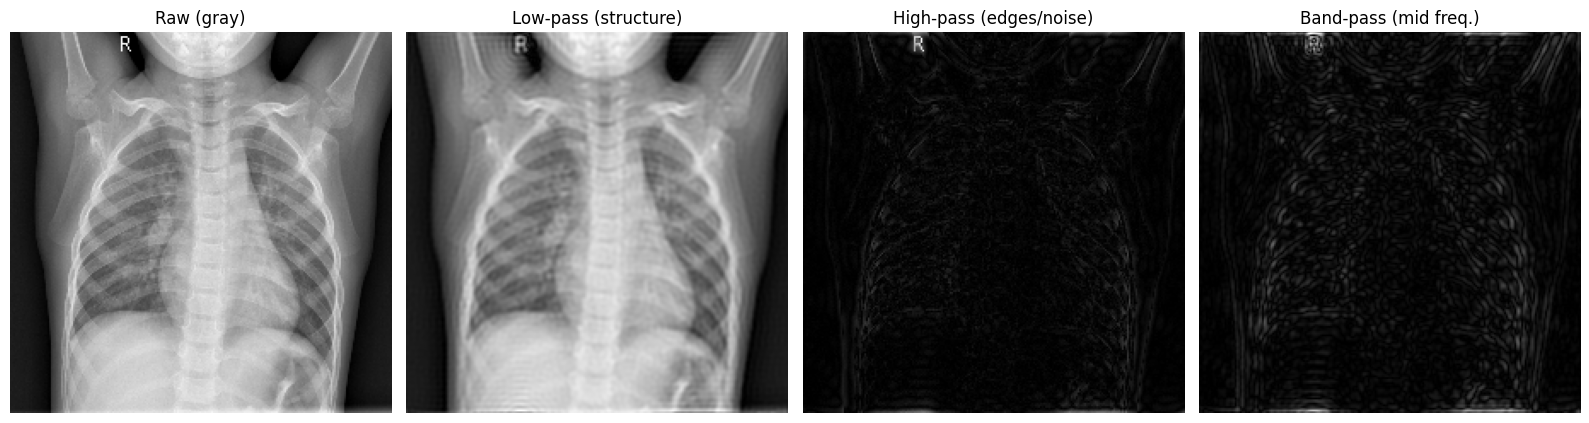

In [6]:
# ==========================================================
# 4. EXPLORATORY VIEW: raw image vs FFT channels
# ==========================================================
# Defined here (before the pipelines) so we can visualize them.
# Radii are in frequency-bin units on a 224x224 grid, as in the original notebook.
R_LOW, R_HIGH = 60, 20

def _minmax255(a):
    a = a.astype(np.float32)
    lo, hi = float(a.min()), float(a.max())
    return (a - lo) / (hi - lo + 1e-8) * 255.0

def fft_bands(gray, r_low=R_LOW, r_high=R_HIGH):
    # gray: float32 (H, W). Returns three images in [0, 255]: low-pass, high-pass, band-pass.
    rows, cols = gray.shape
    dft = cv2.dft(gray.astype(np.float32), flags=cv2.DFT_COMPLEX_OUTPUT)   # shape (H, W, 2): real, imag
    # Shift ONLY the spatial axes. (Shifting all axes would also swap the real/imag channels;
    # the original notebook got the right answer only because the mask is identical in both channels.)
    dft_shift = np.fft.fftshift(dft, axes=(0, 1))
    yy, xx = np.ogrid[:rows, :cols]
    dist_sq = (yy - rows // 2) ** 2 + (xx - cols // 2) ** 2

    def inverse(mask2d):
        m = np.repeat(mask2d[:, :, None].astype(np.float32), 2, axis=2)
        back = cv2.idft(np.fft.ifftshift(dft_shift * m, axes=(0, 1)))
        return _minmax255(cv2.magnitude(back[:, :, 0], back[:, :, 1]))

    low  = inverse(dist_sq <= r_low ** 2)
    high = inverse(dist_sq >= r_high ** 2)
    band = inverse((dist_sq >= r_high ** 2) & (dist_sq <= r_low ** 2))
    return low, high, band

def to_gray(img_rgb):
    return cv2.cvtColor(img_rgb.astype(np.float32), cv2.COLOR_RGB2GRAY)

def fft_pure_np(img_rgb):
    # Model 'fft_pure': three filtered channels only (the raw image is NOT included)
    low, high, band = fft_bands(to_gray(img_rgb))
    return np.stack([low, high, band], axis=-1).astype(np.float32)

def fft_multi_nodc_np(img_rgb):
    # Control: low-pass WITHOUT the DC term (the global mean brightness). High-pass is unchanged.
    gray = to_gray(img_rgb)
    rows, cols = gray.shape
    dft = cv2.dft(gray.astype(np.float32), flags=cv2.DFT_COMPLEX_OUTPUT)
    dft_shift = np.fft.fftshift(dft, axes=(0, 1))
    yy, xx = np.ogrid[:rows, :cols]
    dist_sq = (yy - rows // 2) ** 2 + (xx - cols // 2) ** 2
    m = np.repeat(((dist_sq <= R_LOW**2) & (dist_sq >= 1))[:, :, None].astype(np.float32), 2, axis=2)
    back = cv2.idft(np.fft.ifftshift(dft_shift * m, axes=(0, 1)))
    low = _minmax255(cv2.magnitude(back[:, :, 0], back[:, :, 1]))
    _, high, _ = fft_bands(gray)
    return np.stack([gray, low, high], axis=-1).astype(np.float32)

def jitter_img(img, label):
    # Control: random brightness/contrast on the RAW image (train only). A non-frequency way to
    # reduce intensity shortcuts, which the FFT claim must beat.
    img = tf.image.random_brightness(img, max_delta=40.0)
    img = tf.image.random_contrast(img, 0.7, 1.3)
    return tf.clip_by_value(img, 0.0, 255.0), label

def fft_multi_np(img_rgb):
    # Model 'fft_multi': raw grayscale + low-pass + high-pass
    gray = to_gray(img_rgb)
    low, high, _ = fft_bands(gray)
    return np.stack([gray, low, high], axis=-1).astype(np.float32)

# --- Visual sanity check on one training image ---
sample_path = train_df.path.iloc[0]
img_rgb = cv2.cvtColor(cv2.imread(sample_path, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
img_rgb = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE)).astype(np.float32)
low, high, band = fft_bands(to_gray(img_rgb))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, im, title in zip(axes, [to_gray(img_rgb), low, high, band],
                         ['Raw (gray)', 'Low-pass (structure)', 'High-pass (edges/noise)', 'Band-pass (mid freq.)']):
    ax.imshow(im, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

In [7]:
# ==========================================================
# 5. INPUT PIPELINES
#    Order of operations (important):
#      load -> [augment, TRAIN ONLY] -> feature transform -> batch -> prefetch
#    Augmentation happens BEFORE the FFT, so the FFT sees the augmented image.
#    No .cache() is used: caching float32 224x224 images for ~5k files would exceed Colab RAM.
# ==========================================================
def load_rgb(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])          # float32, values in [0, 255]
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return img, label

augment = tf.keras.Sequential([
    layers.RandomRotation(0.03, fill_mode='nearest'),
    layers.RandomZoom(0.05),
], name='augment')

def augment_img(img, label):
    img = augment(tf.expand_dims(img, 0), training=True)[0]
    return img, label

def numpy_feature(fn):
    def _apply(img, label):
        out = tf.numpy_function(fn, [img], tf.float32)
        out.set_shape([IMG_SIZE, IMG_SIZE, 3])
        return out, label
    return _apply

def densenet_prep(img, label):
    return tf.keras.applications.densenet.preprocess_input(img), label

def vit_prep(img, label):
    # ViT (google/vit-base-patch16-224-in21k) expects inputs in [-1, 1] and channels-first.
    x = img / 127.5 - 1.0
    x = tf.transpose(x, (2, 0, 1))
    return x, label

def make_dataset(df, kind, training, seed=0):
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, df.label.values.astype('float32')))
    if training:
        ds = ds.shuffle(len(df), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(load_rgb, num_parallel_calls=AT)
    if training:
        ds = ds.map(augment_img, num_parallel_calls=AT)
    if kind == 'raw':
        ds = ds.map(densenet_prep, num_parallel_calls=AT)
    elif kind == 'raw_jitter':
        if training:
            ds = ds.map(jitter_img, num_parallel_calls=AT)
        ds = ds.map(densenet_prep, num_parallel_calls=AT)
    elif kind == 'fft_multi_nodc':
        ds = ds.map(numpy_feature(fft_multi_nodc_np), num_parallel_calls=AT).map(densenet_prep, num_parallel_calls=AT)
    elif kind == 'fft_pure':
        ds = ds.map(numpy_feature(fft_pure_np), num_parallel_calls=AT).map(densenet_prep, num_parallel_calls=AT)
    elif kind == 'fft_multi':
        ds = ds.map(numpy_feature(fft_multi_np), num_parallel_calls=AT).map(densenet_prep, num_parallel_calls=AT)
    elif kind == 'vit':
        ds = ds.map(vit_prep, num_parallel_calls=AT)
    else:
        raise ValueError(kind)
    return ds.batch(BATCH_SIZE).prefetch(AT)

def class_weights(labels):
    labels = np.asarray(labels).astype(int)
    n, n0, n1 = len(labels), (labels == 0).sum(), (labels == 1).sum()
    return {0: n / (2.0 * n0), 1: n / (2.0 * n1)}     # standard "balanced" weights

print("Training class weights:", class_weights(train_df.label.values))

Training class weights: {0: np.float64(1.9315004659832247), 1: np.float64(0.6746419270833334)}


## Baseline: pixels + logistic regression

A deliberately simple model. If it already generalizes well, deep learning is not needed for this task. The scaler is fit **only on training pixels**; the original notebook re-fit a new scaler on each external dataset, which normalizes every dataset with its own statistics and hides the very shift we want to measure.

Logistic regression  | test AUC = 0.902 | external AUC = 0.847


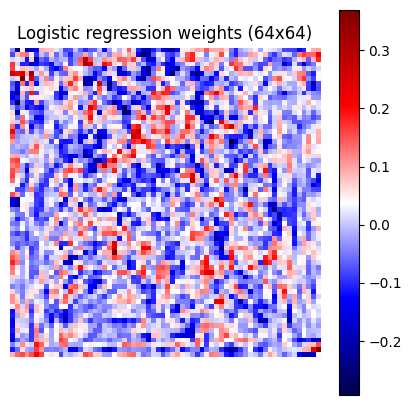

In [8]:
# ==========================================================
# 6. LOGISTIC REGRESSION BASELINE (train-only scaler)
# ==========================================================
def load_gray64(paths):
    X = []
    for p in paths:
        g = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        X.append(cv2.resize(g, (64, 64), interpolation=cv2.INTER_AREA).ravel())
    return np.asarray(X, dtype=np.float32)

X_tr, y_tr = load_gray64(train_df.path), train_df.label.values
X_te, y_te = load_gray64(test_df.path),  test_df.label.values
X_ex, y_ex = load_gray64(ext_df.path),   ext_df.label.values

scaler = StandardScaler().fit(X_tr)                     # FIT ON TRAIN ONLY
lr = LogisticRegression(max_iter=2000, class_weight='balanced')
lr.fit(scaler.transform(X_tr), y_tr)

auc_lr_test = roc_auc_score(y_te, lr.predict_proba(scaler.transform(X_te))[:, 1])
auc_lr_ext  = roc_auc_score(y_ex, lr.predict_proba(scaler.transform(X_ex))[:, 1])
print(f"Logistic regression  | test AUC = {auc_lr_test:.3f} | external AUC = {auc_lr_ext:.3f}")

# Which pixels drive the decision? (Interpret with care; a linear map is not a causal explanation.)
plt.figure(figsize=(5, 5))
plt.imshow(lr.coef_.reshape(64, 64), cmap='seismic')
plt.title("Logistic regression weights (64x64)"); plt.colorbar(); plt.axis('off'); plt.show()

## Models

**Four variants, one training recipe:**

| Key | Input | Backbone |
|---|---|---|
| `raw` | Grayscale-as-RGB image | DenseNet121 (ImageNet) |
| `fft_pure` | Low-pass, high-pass, band-pass (no raw image) | DenseNet121 |
| `fft_multi` | Raw gray, low-pass, high-pass | DenseNet121 |
| `vit` | Raw image in [-1, 1], channels-first | ViT-B/16 (ImageNet-21k) |

**Why `training=False` on the backbone.** With `training=True`, BatchNorm layers normalize with the statistics of the *current batch*. At test time that makes each prediction depend on which other images share its batch. Freezing BatchNorm statistics (`training=False`) is standard for fine-tuning with modest batch sizes. Dropout in the head still behaves normally, because it is controlled by the model's own training flag.

In [9]:
# ==========================================================
# 7. MODEL BUILDERS
# ==========================================================
def build_densenet():
    base = tf.keras.applications.DenseNet121(
        weights=IMAGENET_WEIGHTS, include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = True
    for layer in base.layers[:-UNFREEZE_LAST_N]:
        layer.trainable = False

    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base(inp, training=False)                  # BatchNorm stays in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(DROPOUT)(x)
    out = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    model = models.Model(inp, out)
    model.compile(optimizer=optimizers.Adam(DENSE_LR),
                  loss='binary_crossentropy',
                  metrics=[tf.keras.metrics.AUC(name='auc')])
    return model

class ViTClassifier(tf.keras.Model):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        self.drop = layers.Dropout(0.3)
        self.dense = layers.Dense(128, activation='gelu')
        self.head = layers.Dense(1, activation='sigmoid', dtype='float32')

    def call(self, pixel_values, training=False):
        h = self.backbone(pixel_values=pixel_values, training=training).last_hidden_state
        cls = h[:, 0, :]                            # [CLS] token representation
        x = self.drop(cls, training=training)
        x = self.dense(x)
        return self.head(x)

def build_vit():
    from transformers import TFViTModel           # pip install transformers (plus torch, for from_pt)
    backbone = TFViTModel.from_pretrained('google/vit-base-patch16-224-in21k', from_pt=True)
    m = ViTClassifier(backbone)
    _ = m(tf.zeros((1, 3, IMG_SIZE, IMG_SIZE)))    # build the graph once
    m.compile(optimizer=optimizers.AdamW(learning_rate=VIT_LR, weight_decay=1e-4),
              loss='binary_crossentropy',
              metrics=[tf.keras.metrics.AUC(name='auc')])
    return m

def build_model(kind):
    return build_vit() if kind == 'vit' else build_densenet()

if 'vit' in MODELS:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'transformers', 'torch'], check=False)

In [10]:
# ==========================================================
# 8. EVALUATION HELPERS
# ==========================================================
def predict_all(model, ds):
    y = np.concatenate([yb.numpy() for _, yb in ds]).astype(int)
    p = model.predict(ds, verbose=0).ravel().astype(np.float64)
    return y, p

def bootstrap_auc_ci(y, p, n=N_BOOTSTRAP, seed=0):
    rng = np.random.default_rng(seed)
    idx_all = np.arange(len(y))
    vals = []
    for _ in range(n):
        idx = rng.choice(idx_all, size=len(y), replace=True)
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(roc_auc_score(y[idx], p[idx]))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)

def youden_threshold(y, p):
    # Threshold chosen on VALIDATION data only (maximizes sensitivity + specificity - 1).
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])

def sens_spec(y, p, thr):
    pred = (p >= thr).astype(int)
    tp = np.sum((pred == 1) & (y == 1)); fn = np.sum((pred == 0) & (y == 1))
    tn = np.sum((pred == 0) & (y == 0)); fp = np.sum((pred == 1) & (y == 0))
    return tp / max(tp + fn, 1), tn / max(tn + fp, 1)

In [11]:
# ==========================================================
# 9. TRAIN + EVALUATE ONE (model, seed) RUN
# ==========================================================
def run_one(kind, seed):
    set_seed(seed)
    tf.keras.backend.clear_session()
    gc.collect()

    model  = build_model(kind)
    tr_ds  = make_dataset(train_df, kind, training=True, seed=seed)
    va_ds  = make_dataset(val_df,   kind, training=False)
    cw     = class_weights(train_df.label.values)

    early = callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=PATIENCE,
                                    restore_best_weights=True, verbose=1)
    hist = model.fit(tr_ds, validation_data=va_ds, epochs=EPOCHS,
                     class_weight=cw, callbacks=[early], verbose=2)

    # Threshold from VALIDATION only
    y_val, p_val = predict_all(model, va_ds)
    thr = youden_threshold(y_val, p_val)

    row = dict(model=kind, seed=seed, epochs_run=len(hist.history['loss']),
               val_auc=roc_auc_score(y_val, p_val), threshold=thr)

    # Final, one-time evaluation on the held-out sets
    for name, df in [('test', test_df), ('external', ext_df)]:
        y, p = predict_all(model, make_dataset(df, kind, training=False))
        lo, hi = bootstrap_auc_ci(y, p, seed=seed)
        sens, spec = sens_spec(y, p, thr)
        row[f'{name}_auc']    = roc_auc_score(y, p)
        row[f'{name}_auc_lo'] = lo
        row[f'{name}_auc_hi'] = hi
        row[f'{name}_sens']   = sens
        row[f'{name}_spec']   = spec
        np.savez(os.path.join(OUT_DIR, f'preds_{kind}_seed{seed}_{name}.npz'), y=y, p=p)

    if kind != 'vit' and seed == SEEDS[0]:
        model.save(os.path.join(OUT_DIR, f'{kind}_seed{seed}.keras'))   # kept for Grad-CAM
    del model
    gc.collect()
    return row

In [12]:
# ==========================================================
# 10. EXPERIMENT LOOP (resumable: finished runs are skipped)
# ==========================================================
RESULTS_CSV = os.path.join(OUT_DIR, 'all_runs.csv')
done = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()
rows = done.to_dict('records') if len(done) else []
finished = {(r['model'], int(r['seed'])) for r in rows}

for kind in ALL_KINDS:
    for seed in SEEDS:
        if (kind, seed) in finished:
            print(f"skip (already done): {kind} seed {seed}")
            continue
        print(f"\n===== {kind} | seed {seed} =====")
        rows.append(run_one(kind, seed))
        pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)     # save after EVERY run

results_df = pd.DataFrame(rows)
results_df['gen_gap'] = results_df['test_auc'] - results_df['external_auc']
results_df

skip (already done): raw seed 42
skip (already done): raw seed 123
skip (already done): raw seed 456
skip (already done): fft_pure seed 42
skip (already done): fft_pure seed 123
skip (already done): fft_pure seed 456
skip (already done): fft_multi seed 42
skip (already done): fft_multi seed 123
skip (already done): fft_multi seed 456
skip (already done): raw_jitter seed 42
skip (already done): raw_jitter seed 123
skip (already done): raw_jitter seed 456
skip (already done): fft_multi_nodc seed 42
skip (already done): fft_multi_nodc seed 123

===== fft_multi_nodc | seed 456 =====
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
130/130 - 355s - 3s/step - auc: 0.9490 - loss: 0.3246 - val_auc: 0.9886 - val_loss: 0.1943
Epoch 2/15
130/130 - 168s - 1s/step - auc: 0.9886 - loss: 0.1375 - val_auc: 0.9933 - val_loss: 0.1091
Epoch 3/15
130/130 - 122s - 941ms/step - auc: 0.9935 - loss: 0.1028 - val_auc: 0.9952 - val_loss: 0.0797
Epoch 4/15
130/130 - 142s - 1s/step - auc: 0.9963 - lo

,model,seed,epochs_run,val_auc,threshold,test_auc,test_auc_lo,test_auc_hi,test_sens,test_spec,external_auc,external_auc_lo,external_auc_hi,external_sens,external_spec,gen_gap
0,raw,42,15,0.999461,0.252517,0.946417,0.927863,0.962810,0.997436,0.500000,0.973436,0.968083,0.977923,0.997770,0.647584,-0.027019
1,raw,123,15,0.999401,0.337724,0.962908,0.947859,0.975121,0.997436,0.564103,0.968542,0.963436,0.973505,0.991822,0.652045,-0.005634
2,raw,456,13,0.999029,0.515850,0.954142,0.938326,0.967033,0.997436,0.508547,0.961430,0.954643,0.967634,0.991078,0.582156,-0.007288
3,fft_pure,42,15,0.998290,0.570118,0.953989,0.936292,0.970040,0.994872,0.653846,0.896225,0.884302,0.907733,0.965799,0.570260,0.057764
4,fft_pure,123,15,0.997811,0.621616,0.942264,0.921580,0.961828,0.994872,0.598291,0.883711,0.870935,0.895765,0.975465,0.513011,0.058553
5,fft_pure,456,15,0.998295,0.814906,0.941124,0.921371,0.958602,0.992308,0.688034,0.936136,0.926472,0.943892,0.967286,0.700372,0.004988
6,fft_multi,42,15,0.998750,0.243962,0.957051,0.938248,0.973574,0.994872,0.564103,0.966852,0.960900,0.972433,0.988104,0.686989,-0.009801
7,fft_multi,123,9,0.998597,0.288009,0.960015,0.942857,0.975030,0.997436,0.482906,0.948860,0.941393,0.956263,0.986617,0.499628,0.011156
8,fft_multi,456,11,0.998629,0.567039,0.953342,0.934640,0.968399,0.997436,0.547009,0.959917,0.952527,0.966302,0.980669,0.666171,-0.006575
9,raw_jitter,42,13,0.999187,0.195804,0.961911,0.946975,0.975711,0.997436,0.508547,0.948466,0.940538,0.955326,0.996283,0.390335,0.013445


         model  n_seeds       val AUC test AUC (in-domain)  external AUC generalization gap external sens@thr external spec@thr
           raw        3 0.999 ± 0.000        0.954 ± 0.008 0.968 ± 0.006     -0.013 ± 0.012             0.994             0.627
      fft_pure        3 0.998 ± 0.000        0.946 ± 0.007 0.905 ± 0.027      0.040 ± 0.031             0.970             0.595
     fft_multi        3 0.999 ± 0.000        0.957 ± 0.003 0.959 ± 0.009     -0.002 ± 0.011             0.985             0.618
    raw_jitter        3 0.999 ± 0.000        0.958 ± 0.007 0.964 ± 0.014     -0.007 ± 0.018             0.993             0.616
fft_multi_nodc        3 0.998 ± 0.000        0.944 ± 0.012 0.944 ± 0.021      0.001 ± 0.032             0.980             0.543


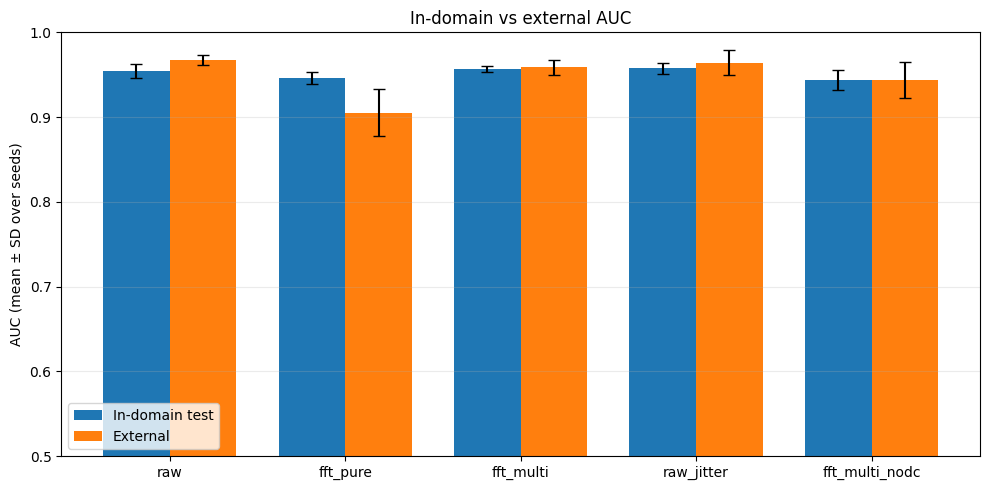

In [13]:
# ==========================================================
# 11. RESULTS: mean ± SD over seeds, with per-run bootstrap CIs
# ==========================================================
def fmt(m, s):
    return f"{m:.3f} ± {s:.3f}"

summary_rows = []
for kind in ALL_KINDS:
    sub = results_df[results_df.model == kind]
    if len(sub) == 0:
        continue
    summary_rows.append({
        'model': kind,
        'n_seeds': len(sub),
        'val AUC': fmt(sub.val_auc.mean(), sub.val_auc.std(ddof=1) if len(sub) > 1 else 0),
        'test AUC (in-domain)': fmt(sub.test_auc.mean(), sub.test_auc.std(ddof=1) if len(sub) > 1 else 0),
        'external AUC': fmt(sub.external_auc.mean(), sub.external_auc.std(ddof=1) if len(sub) > 1 else 0),
        'generalization gap': fmt(sub.gen_gap.mean(), sub.gen_gap.std(ddof=1) if len(sub) > 1 else 0),
        'external sens@thr': f"{sub.external_sens.mean():.3f}",
        'external spec@thr': f"{sub.external_spec.mean():.3f}",
    })
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))
summary.to_csv(os.path.join(OUT_DIR, 'summary_table.csv'), index=False)

# Figure: generated from the data above (no hand-typed numbers)
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(MODELS)); w = 0.38
sub_stats = results_df.groupby('model').agg(
    t_m=('test_auc', 'mean'), t_s=('test_auc', 'std'),
    e_m=('external_auc', 'mean'), e_s=('external_auc', 'std'))
sub_stats = sub_stats.reindex([m for m in ALL_KINDS if m in sub_stats.index])
xs = np.arange(len(sub_stats))
ax.bar(xs - w/2, sub_stats.t_m, w, yerr=sub_stats.t_s.fillna(0), capsize=4, label='In-domain test')
ax.bar(xs + w/2, sub_stats.e_m, w, yerr=sub_stats.e_s.fillna(0), capsize=4, label='External')
ax.set_xticks(xs); ax.set_xticklabels(sub_stats.index)
ax.set_ylim(0.5, 1.0); ax.set_ylabel('AUC (mean ± SD over seeds)')
ax.set_title('In-domain vs external AUC')
ax.legend(); ax.grid(axis='y', alpha=0.25); plt.tight_layout(); plt.show()

## Unsupervised view: PCA and t-SNE (visual check only)

Labels are used only to colour the points. The scaler is fit on the training subset, not on the full dataset as in the original. Clusters in a 2-D projection are **suggestive, not evidence**: t-SNE can separate classes that a classifier would still confuse, and it can merge classes that it would separate.

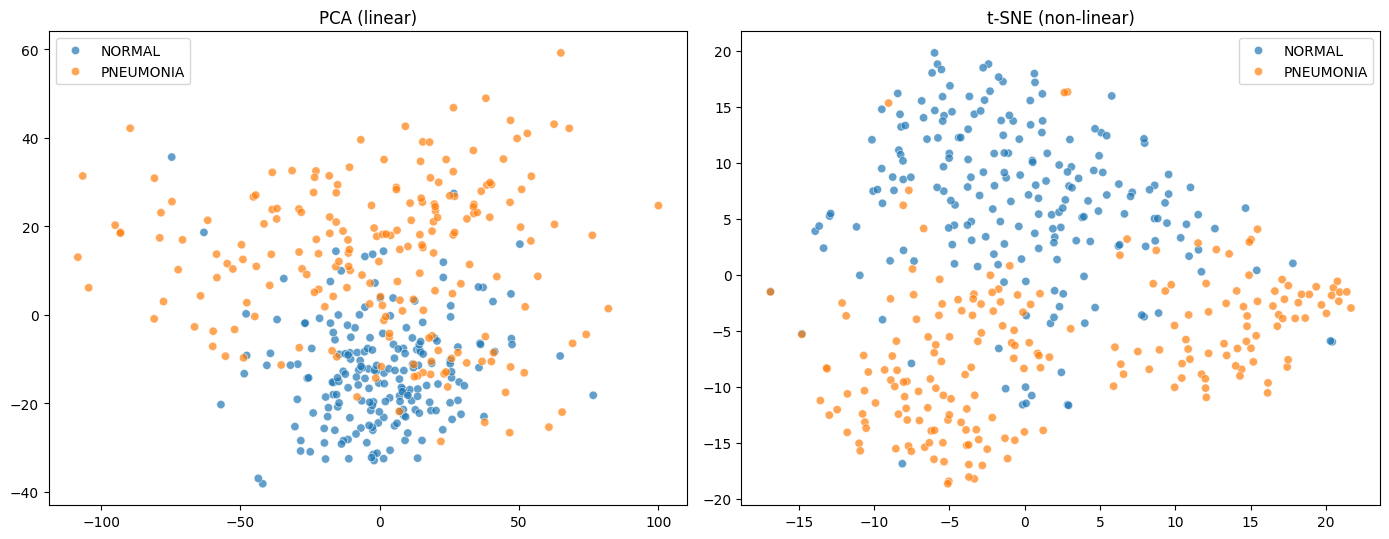

In [14]:
# ==========================================================
# 12. PCA / t-SNE on a balanced training subset (visual only)
# ==========================================================
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

rng = np.random.default_rng(0)
idx0 = rng.choice(np.where(train_df.label.values == 0)[0], size=min(200, (train_df.label == 0).sum()), replace=False)
idx1 = rng.choice(np.where(train_df.label.values == 1)[0], size=min(200, (train_df.label == 1).sum()), replace=False)
sub_idx = np.concatenate([idx0, idx1])
X_sub = X_tr[sub_idx]
y_sub = np.where(train_df.label.values[sub_idx] == 0, 'NORMAL', 'PNEUMONIA')

X_sub_s = StandardScaler().fit(X_tr).transform(X_sub)     # scaler from full TRAIN set, not from this subset
X_pca = PCA(n_components=2, random_state=0).fit_transform(X_sub_s)
X_tsne = TSNE(n_components=2, perplexity=30, random_state=0, init='pca', learning_rate='auto').fit_transform(X_sub_s)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_sub, alpha=0.7, ax=axes[0]); axes[0].set_title('PCA (linear)')
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_sub, alpha=0.7, ax=axes[1]); axes[1].set_title('t-SNE (non-linear)')
plt.tight_layout(); plt.show()

## Grad-CAM: where does each model look?

Grad-CAM weights the last convolutional feature maps by the gradient of the output score with respect to them. It is a *qualitative* tool. Showing a heat map that "looks like lungs" does not by itself prove that a model uses lung tissue. The quantitative version (fraction of attribution inside a lung mask) is listed under next steps.

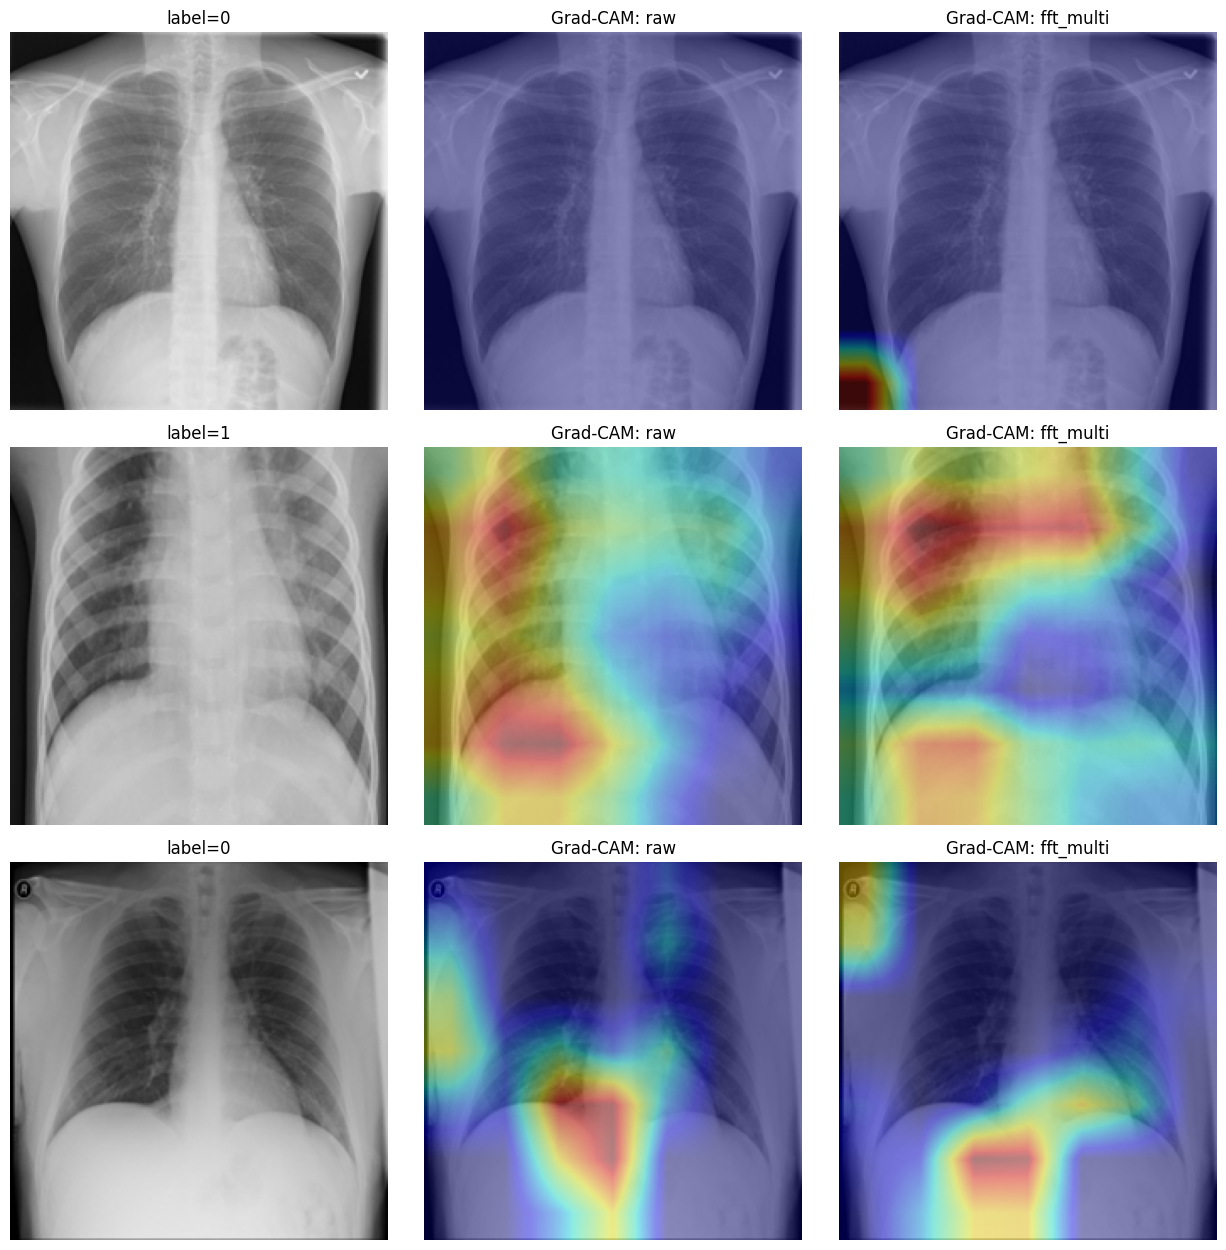

In [15]:
# ==========================================================
# 13. GRAD-CAM (for the DenseNet variants)
# ==========================================================
def gradcam(model, x):
    # x: one preprocessed image, shape (H, W, 3)
    base = [l for l in model.layers if isinstance(l, tf.keras.Model)][0]
    feat_model = tf.keras.Model(base.input, base.get_layer('relu').output)   # last conv features
    gap  = [l for l in model.layers if isinstance(l, layers.GlobalAveragePooling2D)][0]
    head = model.layers[-1]

    xb = tf.expand_dims(tf.cast(x, tf.float32), 0)
    with tf.GradientTape() as tape:
        fmap = feat_model(xb, training=False)
        tape.watch(fmap)
        score = head(gap(fmap))[:, 0]
    grads = tape.gradient(score, fmap)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * fmap, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0].numpy()

def first_seed_model(kind):
    path = os.path.join(OUT_DIR, f'{kind}_seed{SEEDS[0]}.keras')
    return tf.keras.models.load_model(path) if os.path.exists(path) else None

gc_models = {k: first_seed_model(k) for k in ['raw', 'fft_multi']}
gc_models = {k: m for k, m in gc_models.items() if m is not None}

if gc_models:
    rng = np.random.default_rng(1)
    pick = rng.choice(len(ext_df), size=3, replace=False)
    ncol = 1 + len(gc_models)
    fig, axes = plt.subplots(len(pick), ncol, figsize=(4.2 * ncol, 4.2 * len(pick)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(pick):
        row = ext_df.iloc[[i]]
        raw_img = load_rgb(row.path.values[0], 0)[0].numpy().astype(np.uint8)
        axes[r, 0].imshow(raw_img, cmap='gray'); axes[r, 0].set_title(f"label={row.label.values[0]}")
        for c, (kind, model) in enumerate(gc_models.items(), start=1):
            x = next(iter(make_dataset(row, kind, training=False)))[0][0]
            cam = gradcam(model, x)
            axes[r, c].imshow(raw_img, cmap='gray')
            axes[r, c].imshow(cam, cmap='jet', alpha=0.4)
            axes[r, c].set_title(f"Grad-CAM: {kind}")
        for a in axes[r]:
            a.axis('off')
    plt.tight_layout(); plt.show()
else:
    print("No saved DenseNet models found; run the experiment loop first.")

## Results and interpretation (write this AFTER the numbers exist)

Use the summary table above, not the numbers from the earlier notebooks. Good questions to answer in writing:

1. **Primary claim.** Which model has the highest *external* AUC, and is it higher than the raw DenseNet by more than the seed-to-seed spread? With three seeds, state effect sizes with uncertainty rather than p-values.
2. **Generalization gap.** Is the in-domain-to-external drop smaller for FFT models? Compare the `generalization gap` column, not only the external AUC, because a model can have a small gap simply because it is weak in both settings.
3. **Operating point.** Sensitivity and specificity at the validation-chosen threshold show what the model would actually do on new data. A high AUC with poor sensitivity at that threshold is still a problem for clinical use.
4. **Mechanism.** The Grad-CAM panels are illustrations. They can support a hypothesis but cannot establish it.
5. **Label definition.** The external positive class is viral pneumonia (or COVID-19, depending on the setting above). It is not the same label as the training "PNEUMONIA" class, which mixes bacterial and viral pneumonia. Say so explicitly.

Keep these claims out unless a control experiment supports them: "FFT removes shortcut learning", "transformers do not help", "model X is best overall". The ablations in the next steps are what would support such statements.

## Controls: does the FFT claim survive simple alternatives?

Two controls, both trained with the identical recipe:

- **`raw_jitter`**: the raw image with brightness and contrast augmentation on the training set. If this matches the FFT models, then the benefit is about *intensity invariance*, not frequency content.
- **`fft_multi_nodc`**: the multi-channel FFT model with the DC term (global mean brightness) removed from the low-pass channel. If performance depends on this term, the claim that FFT "removes intensity cues" is only partly true.

Interpret these results with the same caution as the main comparison.

In [16]:
# ==========================================================
# 14. SOURCE-IDENTIFICATION DIAGNOSTIC (not a classifier for pneumonia)
#     Can a linear model tell which dataset an image came from?
#     If yes, the domain shift is learnable, and shortcut learning is plausible.
# ==========================================================
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

n_src = min(300, len(train_full), len(ext_df))
X_src_tr = load_gray64(train_full.path.sample(n_src, random_state=0))
X_src_ex = load_gray64(ext_df.path.sample(n_src, random_state=0))
X_src = np.vstack([X_src_tr, X_src_ex])
y_src = np.r_[np.zeros(n_src), np.ones(n_src)]
src_auc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                          X_src, y_src, cv=5, scoring='roc_auc')
print(f"Source identification AUC (5-fold CV): {src_auc.mean():.3f} ± {src_auc.std():.3f}")
print("Near 0.5 -> sources are hard to tell apart with pixels; near 1.0 -> the shift is easy to learn.")

Source identification AUC (5-fold CV): 0.729 ± 0.046
Near 0.5 -> sources are hard to tell apart with pixels; near 1.0 -> the shift is easy to learn.
